<h1>Assignment 4 Task2

<h3>Setup, Drive and paths

In [1]:
import os, json, random, time, urllib.request, zipfile, io
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

DATA_DIR = '/content/data'
os.makedirs(DATA_DIR, exist_ok=True)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


<h3>Downloading Data

In [2]:
TRAIN_TXT = f'{DATA_DIR}/Train_Arabic_Digit.txt'
TEST_TXT  = f'{DATA_DIR}/Test_Arabic_Digit.txt'

if not (os.path.exists(TRAIN_TXT) and os.path.exists(TEST_TXT)):
    url = 'https://archive.ics.uci.edu/static/public/195/spoken+arabic+digit.zip'
    print('Downloading...')
    raw = urllib.request.urlopen(url).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        print(z.namelist())
        for name in z.namelist():
            base = os.path.basename(name).replace(' ', '_')
            if base.lower() in ('train_arabic_digit.txt', 'test_arabic_digit.txt'):
                with open(f'{DATA_DIR}/{base}', 'wb') as f:
                    f.write(z.read(name))
print(os.listdir(DATA_DIR))

Downloading...
['Test_Arabic_Digit.txt', 'Train_Arabic_Digit.txt', 'documentation.html', 'graphic.jpg']
['Test_Arabic_Digit.txt', 'Train_Arabic_Digit.txt']


<h3>Labelling data

In [3]:
def parse_blocks(path):
    """Return list of (T,13) float32 arrays, one per utterance (blank-line separated)."""
    seqs, cur = [], []
    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if line == '':
                if cur:
                    seqs.append(np.array(cur, dtype=np.float32)); cur = []
            else:
                cur.append([float(x) for x in line.split()])
    if cur:
        seqs.append(np.array(cur, dtype=np.float32))
    return seqs

train_seqs = parse_blocks(TRAIN_TXT)
test_seqs  = parse_blocks(TEST_TXT)

n_tr, n_te = len(train_seqs), len(test_seqs)
assert n_tr % 10 == 0 and n_te % 10 == 0, f'Unexpected counts: {n_tr}, {n_te}'
# Labels come from block order: equal-sized consecutive groups for digits 0..9
train_labels = np.repeat(np.arange(10), n_tr // 10)
test_labels  = np.repeat(np.arange(10), n_te // 10)

print('Train utterances:', n_tr, '| Test utterances:', n_te)
print('Per-class train:', np.bincount(train_labels))
print('Per-class test :', np.bincount(test_labels))
lens = np.array([len(s) for s in train_seqs + test_seqs])
print(f'Seq length: min={lens.min()}, max={lens.max()}, mean={lens.mean():.1f}')
print('Feature dim:', train_seqs[0].shape[1])

Train utterances: 6600 | Test utterances: 2200
Per-class train: [660 660 660 660 660 660 660 660 660 660]
Per-class test : [220 220 220 220 220 220 220 220 220 220]
Seq length: min=4, max=93, mean=39.8
Feature dim: 13


<h3>Normalization and Validation split

In [4]:
VAL_FRAC = 0.10
rng = np.random.RandomState(SEED)
tr_idx, val_idx = [], []
for c in range(10):
    idx = np.where(train_labels == c)[0]
    rng.shuffle(idx)
    n_val = int(len(idx) * VAL_FRAC)
    val_idx.extend(idx[:n_val]); tr_idx.extend(idx[n_val:])
tr_idx, val_idx = np.array(sorted(tr_idx)), np.array(sorted(val_idx))

# Normalization stats from the training part only (frame-level)
all_frames = np.concatenate([train_seqs[i] for i in tr_idx], axis=0)
MEAN = all_frames.mean(axis=0)
STD  = all_frames.std(axis=0) + 1e-8

def normalize(seqs):
    return [((s - MEAN) / STD).astype(np.float32) for s in seqs]

X_tr  = normalize([train_seqs[i] for i in tr_idx]);  y_tr  = train_labels[tr_idx]
X_val = normalize([train_seqs[i] for i in val_idx]); y_val = train_labels[val_idx]
X_te  = normalize(test_seqs);                        y_te  = test_labels

print(f'Train: {len(X_tr)}, Val: {len(X_val)}, Test: {len(X_te)}')

Train: 5940, Val: 660, Test: 2200


<h3>Dataset and Padded batching

In [5]:
class MFCCDataset(Dataset):
    def __init__(self, seqs, labels):
        self.seqs, self.labels = seqs, labels
    def __len__(self):
        return len(self.seqs)
    def __getitem__(self, i):
        return torch.from_numpy(self.seqs[i]), int(self.labels[i])

def collate_fn(batch):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([s.shape[0] for s in seqs], dtype=torch.long)
    padded = pad_sequence(seqs, batch_first=True)      # (B, T_max, 13), zero padded
    return padded, lengths, torch.tensor(labels, dtype=torch.long)

BATCH_SIZE = 64

def make_loader(X, y, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(MFCCDataset(X, y), batch_size=BATCH_SIZE, shuffle=shuffle,
                      collate_fn=collate_fn, generator=g if shuffle else None,
                      num_workers=0)

train_loader = make_loader(X_tr,  y_tr,  shuffle=True)
val_loader   = make_loader(X_val, y_val, shuffle=False)
test_loader  = make_loader(X_te,  y_te,  shuffle=False)

# Sanity check
xb, lb, yb = next(iter(train_loader))
print('Batch:', xb.shape, '| lengths:', lb[:8].tolist(), '| labels:', yb[:8].tolist())
packed = pack_padded_sequence(xb, lb, batch_first=True, enforce_sorted=False)
print('Packed OK, total frames:', packed.data.shape[0], '== sum lengths:', int(lb.sum()))

Batch: torch.Size([64, 55, 13]) | lengths: [35, 48, 48, 30, 32, 34, 51, 49] | labels: [0, 4, 6, 0, 7, 1, 6, 4]
Packed OK, total frames: 2643 == sum lengths: 2643


<h3>Mount Drive

In [6]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/rnn_assignment4_take2'
RESULTS_DIR = f'{PROJECT_DIR}/results'       # one .json per finished config
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'   # final model + partial (resume) files
for d in [RESULTS_DIR, CKPT_DIR]:
    os.makedirs(d, exist_ok=True)
print(os.listdir(RESULTS_DIR))

Mounted at /content/drive
['gru_L1_H128.json', 'gru_L3_H128.json', 'gru_L1_H32.json', 'gru_L2_H32.json', 'gru_L2_H128.json', 'gru_L3_H32.json', 'gru_L2_H64.json', 'gru_L3_H64.json', 'lstm_L1_H32.json', 'lstm_L1_H64.json', 'lstm_L2_H128.json', 'lstm_L2_H32.json', 'lstm_L1_H128.json', 'lstm_L2_H64.json', 'lstm_L3_H128.json', 'gru_L1_H64.json', 'rnn_L1_H128.json', 'lstm_L3_H32.json', 'lstm_L3_H64.json', 'rnn_L1_H64.json', 'rnn_L2_H128.json', 'rnn_L2_H64.json', 'rnn_L3_H128.json', 'rnn_L1_H32.json', 'rnn_L2_H32.json', 'rnn_L3_H32.json', 'rnn_L3_H64.json', 'gru_L3_H64_bi_att.json', 'gru_L3_H64_bi.json', 'gru_L3_H64_att.json']


<h3>Class Modelling

In [7]:
class SeqClassifier(nn.Module):
    def __init__(self, cell='lstm', input_size=13, hidden=64, layers=1, num_classes=10,
                 bidirectional=False, attention=False, dropout=0.0):
        super().__init__()
        self.cell, self.bi, self.attention = cell, bidirectional, attention
        rnn_cls = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[cell]
        self.rnn = rnn_cls(input_size=input_size, hidden_size=hidden, num_layers=layers,
                           batch_first=True, bidirectional=bidirectional,
                           dropout=dropout if layers > 1 else 0.0)
        d = hidden * (2 if bidirectional else 1)
        if attention:
            self.att = nn.Linear(d, 1)
        self.fc = nn.Linear(d, num_classes)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        if self.cell == 'lstm':
            h = h[0]                                   # (layers*dirs, B, H)
        if self.attention:
            out, _ = pad_packed_sequence(out, batch_first=True)          # (B, T, d)
            mask = torch.arange(out.size(1), device=out.device)[None, :] < lengths.to(out.device)[:, None]
            scores = self.att(out).squeeze(-1).masked_fill(~mask, -1e9)
            w = torch.softmax(scores, dim=1)
            rep = (w.unsqueeze(-1) * out).sum(dim=1)
        else:
            rep = torch.cat([h[-2], h[-1]], dim=1) if self.bi else h[-1]  # last layer's final state
        return self.fc(rep)

# quick check
m = SeqClassifier('lstm', hidden=64, layers=2).to(DEVICE)
print(m(xb.to(DEVICE), lb).shape, '| params:', sum(p.numel() for p in m.parameters()))

torch.Size([64, 10]) | params: 54154


<h3>Counting no of learnable params

In [8]:
import pandas as pd

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

rows = []
for cell in ['rnn', 'lstm', 'gru']:
    for layers in [1, 2, 3]:
        for hidden in [32, 64, 128]:
            m = SeqClassifier(cell, hidden=hidden, layers=layers)
            rows.append(dict(cell=cell, layers=layers, hidden=hidden,
                             trainable_params=count_trainable(m)))

df_params = pd.DataFrame(rows)

# Long format
print(df_params.to_string(index=False))

# Pivot: one row per (cell, layers), one column per hidden size
pivot = df_params.pivot_table(index=['cell', 'layers'], columns='hidden',
                              values='trainable_params')
print(pivot)

cell  layers  hidden  trainable_params
 rnn       1      32              1834
 rnn       1      64              5706
 rnn       1     128             19594
 rnn       2      32              3946
 rnn       2      64             14026
 rnn       2     128             52618
 rnn       3      32              6058
 rnn       3      64             22346
 rnn       3     128             85642
lstm       1      32              6346
lstm       1      64             20874
lstm       1     128             74506
lstm       2      32             14794
lstm       2      64             54154
lstm       2     128            206602
lstm       3      32             23242
lstm       3      64             87434
lstm       3     128            338698
 gru       1      32              4842
 gru       1      64             15818
 gru       1     128             56202
 gru       2      32             11178
 gru       2      64             40778
 gru       2     128            155274
 gru       3      32     

<h3>Training

In [9]:
LR = 1e-3
CLIP = 5.0
TOL = 1e-4          # |L_k - L_{k-1}| < 1e-4  -> stop
MAX_EPOCHS = 150    # safety cap only; mention it in the report

def cfg_name(c):
    s = f"{c['cell']}_L{c['layers']}_H{c['hidden']}"
    if c.get('bidirectional'): s += '_bi'
    if c.get('attention'):     s += '_att'
    return s

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction='sum')
    tot_loss, correct, n = 0.0, 0, 0
    preds, labels = [], []
    for x, l, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x, l)
        tot_loss += crit(out, y).item()
        p = out.argmax(1)
        correct += (p == y).sum().item(); n += y.numel()
        preds += p.cpu().tolist(); labels += y.cpu().tolist()
    return tot_loss / n, correct / n, preds, labels

def run_config(cfg, verbose_every=50):
    name = cfg_name(cfg)
    res_path  = f'{RESULTS_DIR}/{name}.json'
    ckpt_path = f'{CKPT_DIR}/{name}.pt'
    part_path = f'{CKPT_DIR}/{name}_partial.pt'

    if os.path.exists(res_path):                       # already done -> skip
        print(f'[SKIP] {name} (result exists)')
        with open(res_path) as f: return json.load(f)

    set_seed(SEED)
    model = SeqClassifier(cfg['cell'], hidden=cfg['hidden'], layers=cfg['layers'],
                          bidirectional=cfg.get('bidirectional', False),
                          attention=cfg.get('attention', False),
                          dropout=cfg.get('dropout', 0.0)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()
    tr_loader = make_loader(X_tr, y_tr, shuffle=True)
    tr_eval   = make_loader(X_tr, y_tr, shuffle=False)

    hist = dict(loss=[], g_total=[], g_first=[], g_last=[])
    start, elapsed_prev = 0, 0.0
    if os.path.exists(part_path):                      # resume an interrupted config
        ck = torch.load(part_path, map_location=DEVICE)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        hist, start, elapsed_prev = ck['hist'], ck['epoch'], ck['elapsed']
        print(f'[RESUME] {name} from epoch {start}')

    first_w = model.rnn.weight_ih_l0
    last_w  = getattr(model.rnn, f'weight_ih_l{cfg["layers"] - 1}')
    t0, converged = time.time(), False

    for epoch in range(start, MAX_EPOCHS):
        model.train()
        tot, n, gt, gf, gl, nb = 0.0, 0, 0.0, 0.0, 0.0, 0
        for x, l, y in tr_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(x, l), y)
            loss.backward()
            gt += nn.utils.clip_grad_norm_(model.parameters(), CLIP).item()  # norm before clipping
            gf += first_w.grad.norm().item(); gl += last_w.grad.norm().item(); nb += 1
            opt.step()
            tot += loss.item() * y.size(0); n += y.size(0)
        ep_loss = tot / n                                # average training error of this epoch
        hist['loss'].append(ep_loss); hist['g_total'].append(gt / nb)
        hist['g_first'].append(gf / nb); hist['g_last'].append(gl / nb)

        # if (epoch + 1) % verbose_every == 0 or epoch == 0:
        #     print(f'{name} | epoch {epoch+1:3d} | loss {ep_loss:.5f}')
        if (epoch + 1) % verbose_every == 0:
            print(f'{name} | epoch {epoch+1:3d} | loss {ep_loss:.5f}')
        if epoch > 0 and abs(hist['loss'][-1] - hist['loss'][-2]) < TOL:
            converged = True
            print(f'{name} | converged at epoch {epoch+1} (|dL|={abs(hist["loss"][-1]-hist["loss"][-2]):.2e})')
            break
        if (epoch + 1) % 5 == 0:                         # save resume point
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), hist=hist,
                            epoch=epoch + 1, elapsed=elapsed_prev + time.time() - t0), part_path)


    _, tr_acc, _, _ = evaluate(model, tr_eval)
    _, va_acc, _, _ = evaluate(model, val_loader)
    res = dict(name=name, cfg=cfg, epochs=len(hist['loss']), converged=converged,
               train_acc=tr_acc, val_acc=va_acc,
               n_params=sum(p.numel() for p in model.parameters()),
               time_sec=elapsed_prev + time.time() - t0,
               loss_hist=hist['loss'], g_total=hist['g_total'],
               g_first=hist['g_first'], g_last=hist['g_last'])
    torch.save(model.state_dict(), ckpt_path)
    with open(res_path, 'w') as f: json.dump(res, f)
    if os.path.exists(part_path): os.remove(part_path)
    print(f'[DONE] {name} | train {tr_acc:.4f} | val {va_acc:.4f} | epochs {res["epochs"]}')
    return res

def run_group(cell, layers, hidden_list=(32, 64, 128)):
    return [run_config(dict(cell=cell, layers=layers, hidden=h)) for h in hidden_list]

In [10]:
# Cell 9
r = run_group('rnn', 1)

[SKIP] rnn_L1_H32 (result exists)
[SKIP] rnn_L1_H64 (result exists)
[SKIP] rnn_L1_H128 (result exists)


In [11]:
# Cell 10
r = run_group('rnn', 2)

[SKIP] rnn_L2_H32 (result exists)
[SKIP] rnn_L2_H64 (result exists)
[SKIP] rnn_L2_H128 (result exists)


In [12]:
# Cell 10
r = run_group('rnn', 3)

[SKIP] rnn_L3_H32 (result exists)
[SKIP] rnn_L3_H64 (result exists)
[SKIP] rnn_L3_H128 (result exists)


In [13]:
# Cell 12
r = run_group('lstm', 1)

[SKIP] lstm_L1_H32 (result exists)
[SKIP] lstm_L1_H64 (result exists)
[SKIP] lstm_L1_H128 (result exists)


In [14]:
# Cell 12
r = run_group('lstm', 2)

[SKIP] lstm_L2_H32 (result exists)
[SKIP] lstm_L2_H64 (result exists)
[SKIP] lstm_L2_H128 (result exists)


In [15]:
# Cell 12
r = run_group('lstm', 3)

[SKIP] lstm_L3_H32 (result exists)
[SKIP] lstm_L3_H64 (result exists)
[SKIP] lstm_L3_H128 (result exists)


In [16]:
# Cell 15
r = run_group('gru', 1)

[SKIP] gru_L1_H32 (result exists)
[SKIP] gru_L1_H64 (result exists)
[SKIP] gru_L1_H128 (result exists)


In [17]:
# Cell 15
r = run_group('gru', 2)

[SKIP] gru_L2_H32 (result exists)
[SKIP] gru_L2_H64 (result exists)
[SKIP] gru_L2_H128 (result exists)


In [18]:
# Cell 15
r = run_group('gru', 3)

[SKIP] gru_L3_H32 (result exists)
[SKIP] gru_L3_H64 (result exists)
[SKIP] gru_L3_H128 (result exists)


<h3>Summary table

In [19]:
import glob

def eval_test_for_saved(only_names=None):
    for p in sorted(glob.glob(f'{RESULTS_DIR}/*.json')):
        with open(p) as f: r = json.load(f)
        if only_names and r['name'] not in only_names: continue
        if 'test_acc' in r:
            continue
        c = r['cfg']
        model = SeqClassifier(c['cell'], hidden=c['hidden'], layers=c['layers'],
                              bidirectional=c.get('bidirectional', False),
                              attention=c.get('attention', False)).to(DEVICE)
        model.load_state_dict(torch.load(f"{CKPT_DIR}/{r['name']}.pt", map_location=DEVICE))
        _, te_acc, te_pred, te_true = evaluate(model, test_loader)
        r.update(test_acc=te_acc, test_pred=te_pred, test_true=te_true)
        with open(p, 'w') as f: json.dump(r, f)
        print(f"{r['name']} | test {te_acc:.4f}")

eval_test_for_saved()

<h3>Load results and plot loss vs. epoch for every config

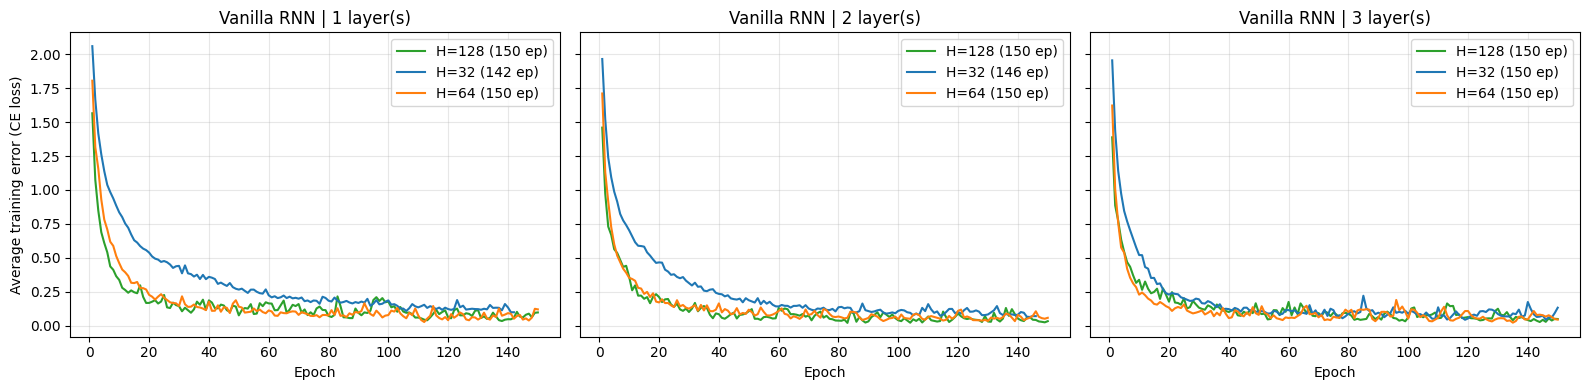

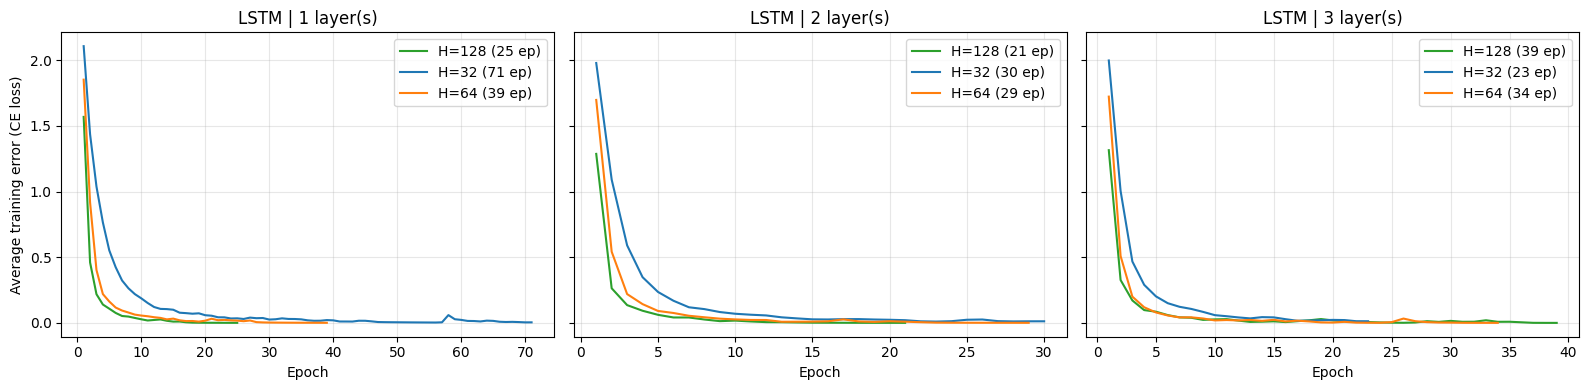

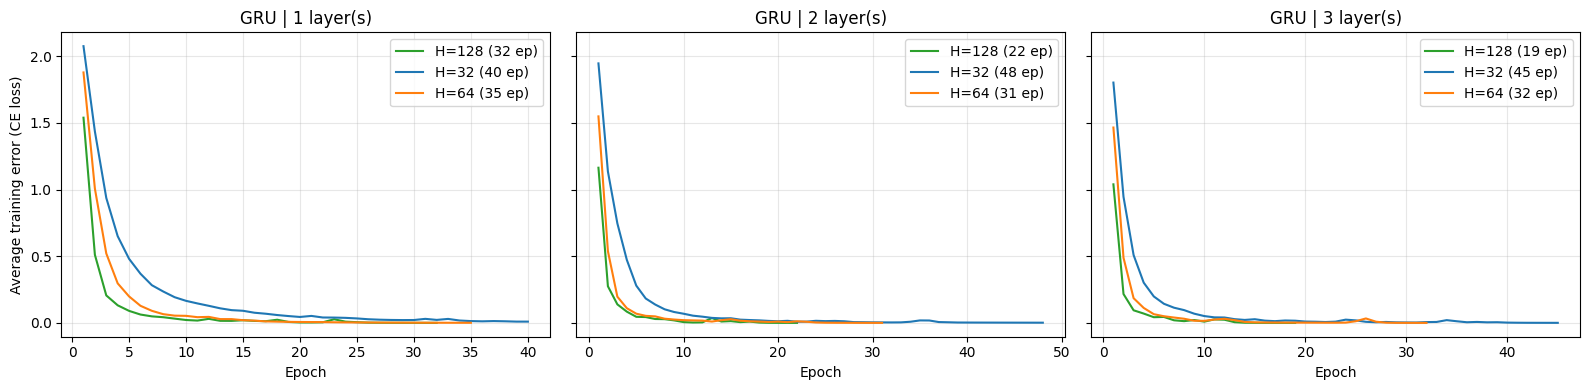

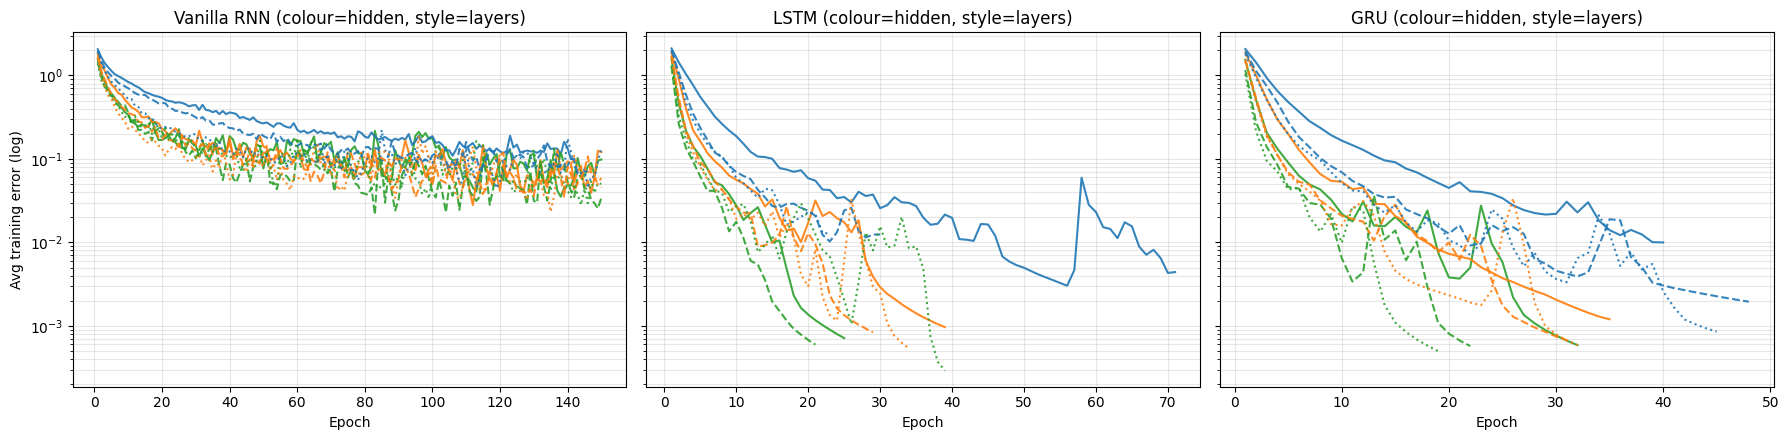

In [21]:
import glob, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

FIG_DIR = f'{PROJECT_DIR}/figures'; os.makedirs(FIG_DIR, exist_ok=True)

def load_results(bonus=False):
    out = []
    for p in sorted(glob.glob(f'{RESULTS_DIR}/*.json')):
        r = json.load(open(p)); c = r['cfg']
        if (c.get('bidirectional', False) or c.get('attention', False)) == bonus:
            out.append(r)
    return out

base = load_results(bonus=False)
CELLS = {'rnn': 'Vanilla RNN', 'lstm': 'LSTM', 'gru': 'GRU'}
COL = {32: 'tab:blue', 64: 'tab:orange', 128: 'tab:green'}

# One figure per cell type: columns = #layers, lines = hidden size
for cell, cname in CELLS.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for ax, L in zip(axes, [1, 2, 3]):
        for r in base:
            c = r['cfg']
            if c['cell'] == cell and c['layers'] == L:
                ep = np.arange(1, len(r['loss_hist']) + 1)
                ax.plot(ep, r['loss_hist'], color=COL[c['hidden']], label=f"H={c['hidden']} ({r['epochs']} ep)")
        ax.set_title(f'{cname} | {L} layer(s)'); ax.set_xlabel('Epoch'); ax.grid(alpha=.3)
        ax.legend()
    axes[0].set_ylabel('Average training error (CE loss)')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/loss_{cell}.png', dpi=150); plt.show()

# Overview: all 27 curves, log-y so convergence tails are visible
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (cell, cname) in zip(axes, CELLS.items()):
    for r in base:
        c = r['cfg']
        if c['cell'] == cell:
            ax.plot(np.arange(1, len(r['loss_hist']) + 1), r['loss_hist'],
                    ls={1: '-', 2: '--', 3: ':'}[c['layers']], color=COL[c['hidden']], alpha=.9)
    ax.set_yscale('log'); ax.set_title(f'{cname} (colour=hidden, style=layers)')
    ax.set_xlabel('Epoch'); ax.grid(alpha=.3, which='both')
axes[0].set_ylabel('Avg training error (log)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/loss_overview.png', dpi=150); plt.show()

<h3>Summary Table

In [22]:


from IPython.display import display
eval_test_for_saved()                      # makes sure test_acc exists in every JSON

def make_table(results):
    rows = []
    for r in results:
        c = r['cfg']
        rows.append(dict(cell=c['cell'], layers=c['layers'], hidden=c['hidden'],
                         bidir=c.get('bidirectional', False), attn=c.get('attention', False),
                         params=r['n_params'], epochs=r['epochs'], converged=r['converged'],
                         train_acc=r['train_acc'], val_acc=r['val_acc'], test_acc=r['test_acc'],
                         gap=r['train_acc'] - r['test_acc'], time_s=round(r['time_sec'])))
    return pd.DataFrame(rows).sort_values(['cell', 'layers', 'hidden']).reset_index(drop=True)

df = make_table(base)
df.to_csv(f'{FIG_DIR}/summary_all_configs.csv', index=False)

best_idx = df.sort_values(['val_acc', 'params'], ascending=[False, True]).index[0]
def mark_best(row):
    return ['font-weight:bold; background-color:#fff3b0' if row.name == best_idx else '' for _ in row]

display(df.style
        .apply(mark_best, axis=1)
        .background_gradient(subset=['test_acc'], cmap='Greens')
        .format({'train_acc': '{:.4f}', 'val_acc': '{:.4f}', 'test_acc': '{:.4f}', 'gap': '{:.4f}'})
        .set_caption('All 27 configs (yellow row = best by validation accuracy)'))

# Compact pivots
for metric in ['train_acc', 'test_acc', 'epochs']:
    print(f'\n=== {metric} ===')
    print(df.pivot_table(index=['cell', 'layers'], columns='hidden', values=metric).round(4))
print('\nNot converged within MAX_EPOCHS:', df[~df.converged][['cell', 'layers', 'hidden']].values.tolist())

,cell,layers,hidden,bidir,attn,params,epochs,converged,train_acc,val_acc,test_acc,gap,time_s
0,gru,1,32,False,False,4842,40,True,0.9995,0.9939,0.9345,0.0649,23
1,gru,1,64,False,False,15818,35,True,1.0000,0.9864,0.9459,0.0541,21
2,gru,1,128,False,False,56202,32,True,1.0000,0.9970,0.9705,0.0295,19
3,gru,2,32,False,False,11178,48,True,0.9998,0.9970,0.9632,0.0366,39
4,gru,2,64,False,False,40778,31,True,1.0000,0.9970,0.9595,0.0405,26
5,gru,2,128,False,False,155274,22,True,1.0000,0.9985,0.9700,0.0300,19
6,gru,3,32,False,False,17514,45,True,1.0000,0.9970,0.9573,0.0427,48
7,gru,3,64,False,False,65738,32,True,1.0000,1.0000,0.9600,0.0400,34
8,gru,3,128,False,False,254346,19,True,1.0000,0.9985,0.9695,0.0305,22
9,lstm,1,32,False,False,6346,71,True,0.9998,0.9924,0.9477,0.0521,41



=== train_acc ===
hidden          32      64      128
cell layers                        
gru  1       0.9995  1.0000  1.0000
     2       0.9998  1.0000  1.0000
     3       1.0000  1.0000  1.0000
lstm 1       0.9998  1.0000  1.0000
     2       0.9983  1.0000  1.0000
     3       0.9955  1.0000  1.0000
rnn  1       0.9758  0.9722  0.9813
     2       0.9791  0.9909  0.9951
     3       0.9443  0.9912  0.9894

=== test_acc ===
hidden          32      64      128
cell layers                        
gru  1       0.9345  0.9459  0.9705
     2       0.9632  0.9595  0.9700
     3       0.9573  0.9600  0.9695
lstm 1       0.9477  0.9473  0.9705
     2       0.9514  0.9577  0.9577
     3       0.9500  0.9636  0.9623
rnn  1       0.8586  0.8873  0.9064
     2       0.9018  0.9236  0.9427
     3       0.8673  0.9409  0.9259

=== epochs ===
hidden         32     64     128
cell layers                     
gru  1        40.0   35.0   32.0
     2        48.0   31.0   22.0
     3        45.0   32

<h3>best configuration: train/test accuracy and full confusion matrix

### Best overall (vanilla grid): gru_L3_H64  (params=65738, epochs=32)
Final training accuracy: 1.0000 | Validation: 1.0000 | Test accuracy: 0.9600
              precision    recall  f1-score   support

           0     0.8589    0.9682    0.9103       220
           1     0.9909    0.9909    0.9909       220
           2     0.9559    0.9864    0.9709       220
           3     0.9587    0.9500    0.9543       220
           4     0.9726    0.9682    0.9704       220
           5     0.9556    0.9773    0.9663       220
           6     1.0000    0.8545    0.9216       220
           7     0.9631    0.9500    0.9565       220
           8     0.9677    0.9545    0.9611       220
           9     0.9955    1.0000    0.9977       220

    accuracy                         0.9600      2200
   macro avg     0.9619    0.9600    0.9600      2200
weighted avg     0.9619    0.9600    0.9600      2200



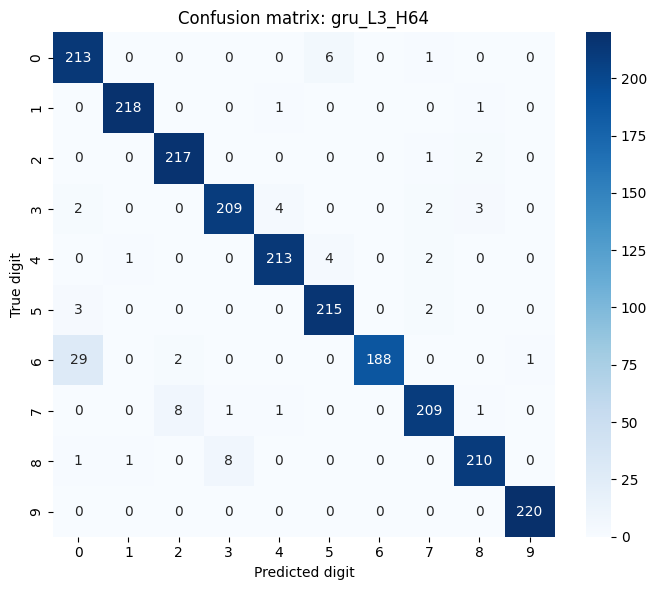

### Best Vanilla RNN: rnn_L2_H128  (params=52618, epochs=150)
Final training accuracy: 0.9951 | Validation: 0.9788 | Test accuracy: 0.9427
              precision    recall  f1-score   support

           0     0.8739    0.9455    0.9083       220
           1     0.9815    0.9636    0.9725       220
           2     0.9298    0.9636    0.9464       220
           3     0.8929    0.9091    0.9009       220
           4     0.9595    0.9682    0.9638       220
           5     0.9417    0.9545    0.9481       220
           6     0.9946    0.8409    0.9113       220
           7     0.9498    0.9455    0.9476       220
           8     0.9541    0.9455    0.9498       220
           9     0.9646    0.9909    0.9776       220

    accuracy                         0.9427      2200
   macro avg     0.9442    0.9427    0.9426      2200
weighted avg     0.9442    0.9427    0.9426      2200



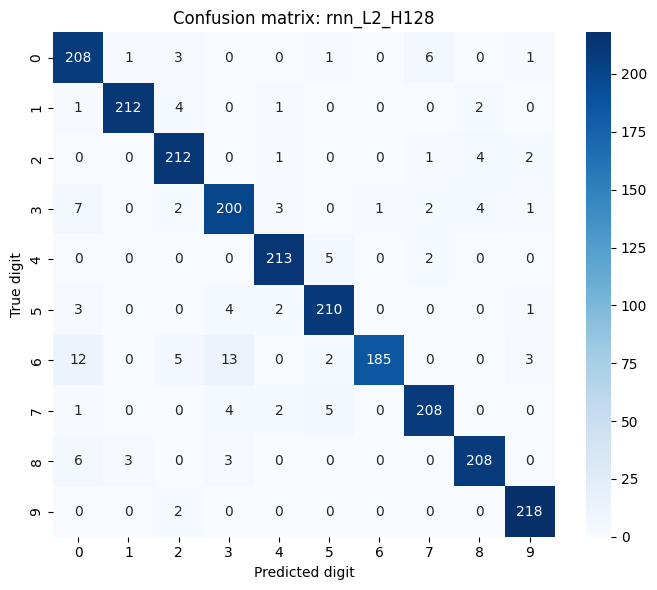

### Best LSTM: lstm_L2_H64  (params=54154, epochs=29)
Final training accuracy: 1.0000 | Validation: 0.9985 | Test accuracy: 0.9577
              precision    recall  f1-score   support

           0     0.8411    0.9864    0.9079       220
           1     0.9818    0.9818    0.9818       220
           2     0.9773    0.9773    0.9773       220
           3     0.9712    0.9182    0.9439       220
           4     0.9596    0.9727    0.9661       220
           5     0.9725    0.9636    0.9680       220
           6     1.0000    0.8864    0.9398       220
           7     0.9251    0.9545    0.9396       220
           8     0.9811    0.9455    0.9630       220
           9     0.9954    0.9909    0.9932       220

    accuracy                         0.9577      2200
   macro avg     0.9605    0.9577    0.9581      2200
weighted avg     0.9605    0.9577    0.9581      2200



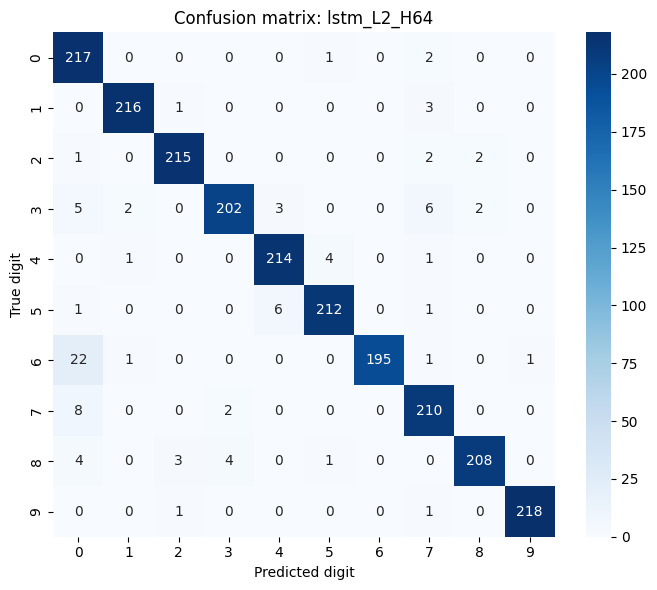

### Best GRU: gru_L3_H64  (params=65738, epochs=32)
Final training accuracy: 1.0000 | Validation: 1.0000 | Test accuracy: 0.9600
              precision    recall  f1-score   support

           0     0.8589    0.9682    0.9103       220
           1     0.9909    0.9909    0.9909       220
           2     0.9559    0.9864    0.9709       220
           3     0.9587    0.9500    0.9543       220
           4     0.9726    0.9682    0.9704       220
           5     0.9556    0.9773    0.9663       220
           6     1.0000    0.8545    0.9216       220
           7     0.9631    0.9500    0.9565       220
           8     0.9677    0.9545    0.9611       220
           9     0.9955    1.0000    0.9977       220

    accuracy                         0.9600      2200
   macro avg     0.9619    0.9600    0.9600      2200
weighted avg     0.9619    0.9600    0.9600      2200



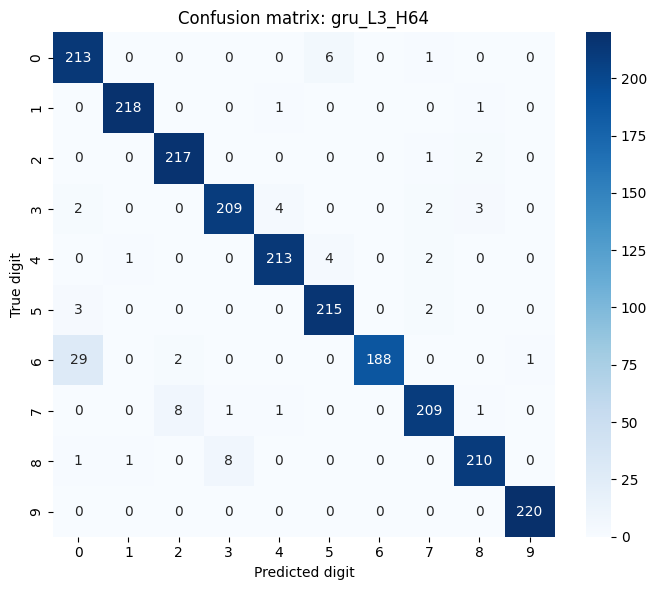

,cell,config,train,val,test,params,epochs
0,rnn,rnn_L2_H128,0.9951,0.9788,0.9427,52618,150
1,lstm,lstm_L2_H64,1.0000,0.9985,0.9577,54154,29
2,gru,gru_L3_H64,1.0000,1.0000,0.9600,65738,32


In [23]:
import seaborn as sns
tr_eval_loader = make_loader(X_tr, y_tr, shuffle=False)

def load_model(r):
    c = r['cfg']
    m = SeqClassifier(c['cell'], hidden=c['hidden'], layers=c['layers'],
                      bidirectional=c.get('bidirectional', False),
                      attention=c.get('attention', False)).to(DEVICE)
    m.load_state_dict(torch.load(f"{CKPT_DIR}/{r['name']}.pt", map_location=DEVICE))
    return m

def report_best(r, title):
    m = load_model(r)
    _, tr_acc, _, _ = evaluate(m, tr_eval_loader)
    _, te_acc, pred, true = evaluate(m, test_loader)
    cm = confusion_matrix(true, pred, labels=range(10))
    print(f'### {title}: {r["name"]}  (params={r["n_params"]}, epochs={r["epochs"]})')
    print(f'Final training accuracy: {tr_acc:.4f} | Validation: {r["val_acc"]:.4f} | Test accuracy: {te_acc:.4f}')
    print(classification_report(true, pred, digits=4))
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
    plt.xlabel('Predicted digit'); plt.ylabel('True digit'); plt.title(f'Confusion matrix: {r["name"]}')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/cm_{r["name"]}.png', dpi=150); plt.show()
    return cm

# Overall best (selected by VALIDATION accuracy, ties -> fewer params)
pick = lambda rs: max(rs, key=lambda r: (r['val_acc'], -r['n_params']))
best_overall = pick(base)
cm_best = report_best(best_overall, 'Best overall (vanilla grid)')

# Best per cell type (needed for the RNN vs LSTM vs GRU comparison)
best_by_cell = {}
for cell, cname in CELLS.items():
    best_by_cell[cell] = pick([r for r in base if r['cfg']['cell'] == cell])
    report_best(best_by_cell[cell], f'Best {cname}')

pd.DataFrame([dict(cell=k, config=v['name'], train=v['train_acc'], val=v['val_acc'], test=v['test_acc'],
                   params=v['n_params'], epochs=v['epochs']) for k, v in best_by_cell.items()]).round(4)

<h3>MFCC heatmaps for sample utterances (one per digit)

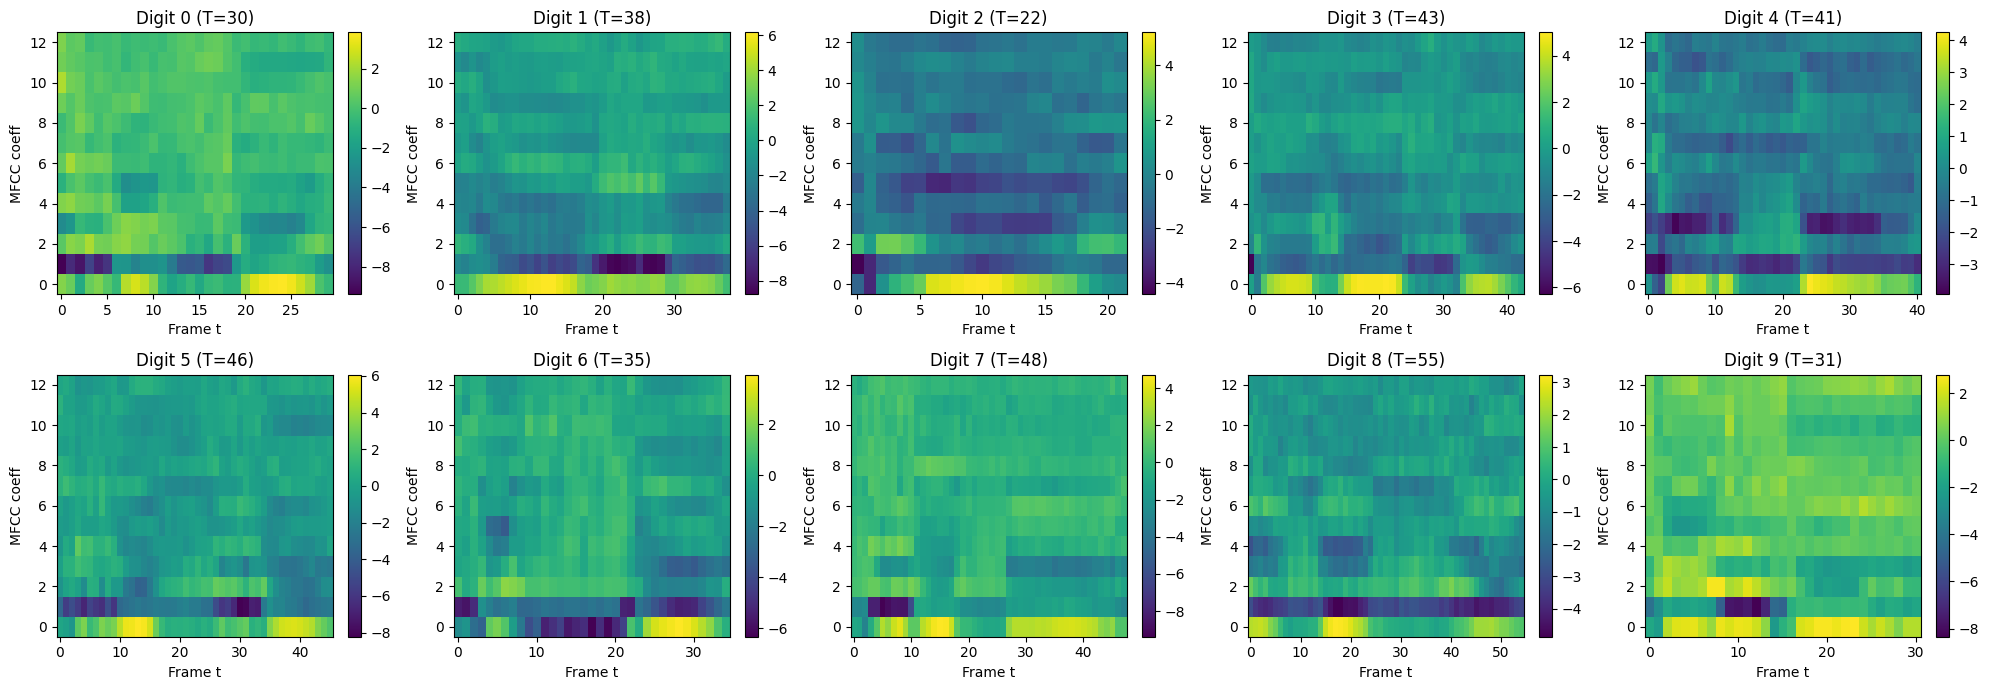

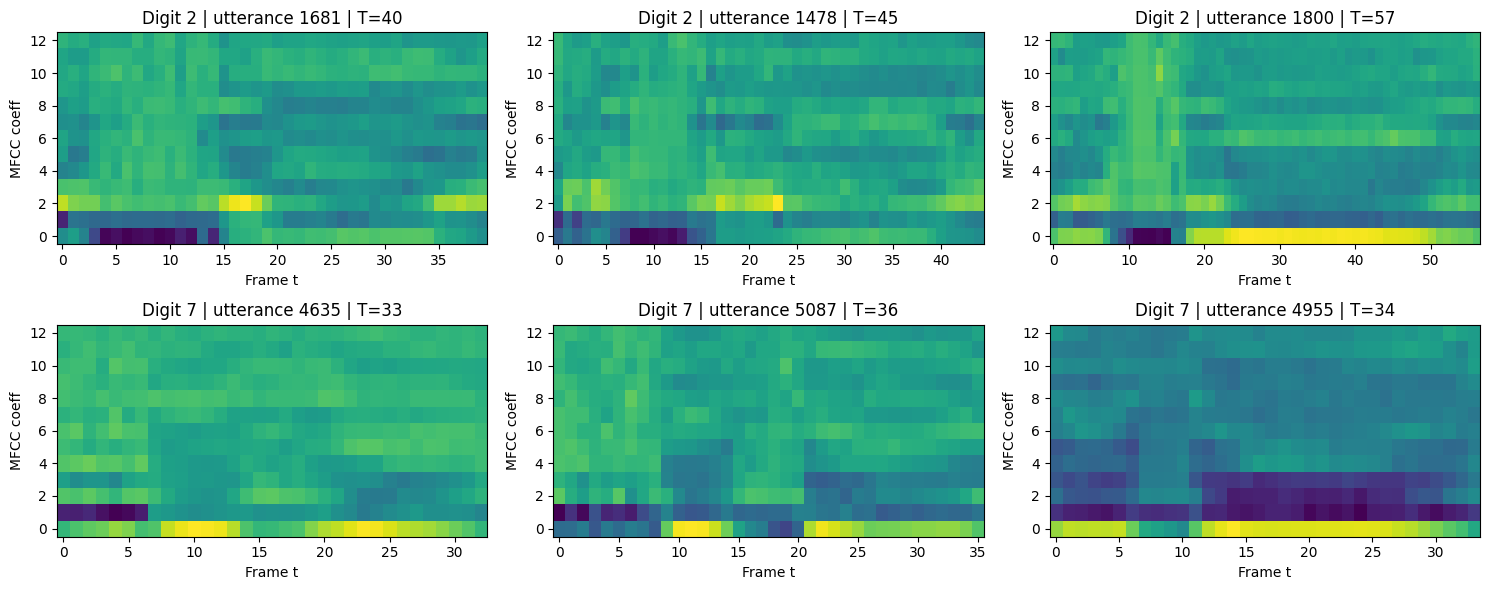

In [24]:
# Raw (un-normalised) MFCCs, one utterance per digit class
rs = np.random.RandomState(SEED)
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for d, ax in enumerate(axes.ravel()):
    idx = rs.choice(np.where(train_labels == d)[0])
    s = train_seqs[idx]                                   # (T, 13)
    im = ax.imshow(s.T, aspect='auto', origin='lower', cmap='viridis')
    ax.set_title(f'Digit {d} (T={s.shape[0]})'); ax.set_xlabel('Frame t'); ax.set_ylabel('MFCC coeff')
    ax.set_yticks(range(0, 13, 2))
    fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/mfcc_heatmaps.png', dpi=150); plt.show()

# Same digit, 3 different speakers: shows intra-class variability and length variation
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for row, d in enumerate([2, 7]):
    for col, idx in enumerate(rs.choice(np.where(train_labels == d)[0], 3, replace=False)):
        s = train_seqs[idx]
        axes[row, col].imshow(s.T, aspect='auto', origin='lower', cmap='viridis')
        axes[row, col].set_title(f'Digit {d} | utterance {idx} | T={s.shape[0]}')
        axes[row, col].set_xlabel('Frame t'); axes[row, col].set_ylabel('MFCC coeff')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/mfcc_same_digit.png', dpi=150); plt.show()

<h3>Gradient-flow analysis

hidden         32     64     128
cell layers                     
gru  1       1.000  1.000  1.000
     2       1.933  2.230  2.373
     3       2.695  2.411  2.721
lstm 1       1.000  1.000  1.000
     2       0.994  1.370  1.746
     3       0.849  1.518  2.327
rnn  1       1.000  1.000  1.000
     2       1.389  1.442  1.525
     3       1.196  1.566  1.493
hidden          32     64     128
cell layers                      
gru  1        0.789  0.426  0.430
     2        0.448  0.393  0.443
     3        0.453  0.324  0.429
lstm 1        1.171  0.794  0.892
     2        1.411  0.670  0.541
     3        1.538  0.638  0.542
rnn  1       12.247  6.559  8.166
     2        8.439  5.109  3.676
     3        7.183  3.552  3.661


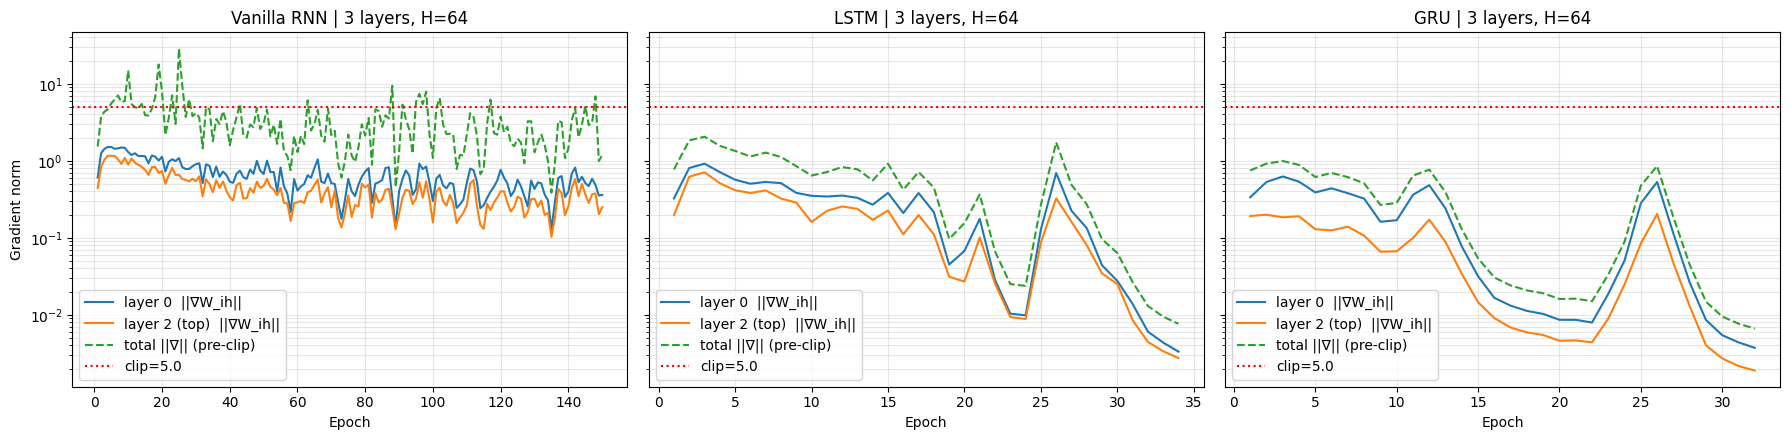

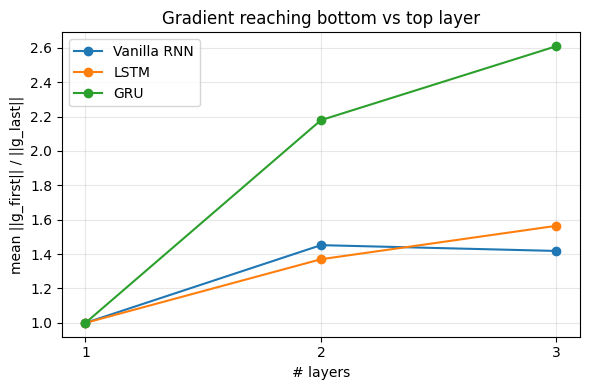

In [25]:
# g_first = ||dL/dW_ih of layer 0||, g_last = ||dL/dW_ih of top layer|| (epoch averages, before clipping)
# For 1-layer models first == last (ratio 1). Vanishing gradients show up as g_first << g_last in deep models.
rows = []
for r in base:
    c = r['cfg']; gf, gl, gt = map(np.array, (r['g_first'], r['g_last'], r['g_total']))
    rows.append(dict(cell=c['cell'], layers=c['layers'], hidden=c['hidden'],
                     mean_g_total=gt.mean(), mean_g_first=gf.mean(), mean_g_last=gl.mean(),
                     ratio_first_over_last=(gf / (gl + 1e-12)).mean(), pct_epochs_gt_clip=(gt > CLIP).mean() * 100))
dfg = pd.DataFrame(rows)
print(dfg.pivot_table(index=['cell', 'layers'], columns='hidden', values='ratio_first_over_last').round(3))
print(dfg.pivot_table(index=['cell', 'layers'], columns='hidden', values='mean_g_total').round(3))

# Curves for the 3-layer, H=64 models: first-layer vs last-layer vs total gradient norm
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (cell, cname) in zip(axes, CELLS.items()):
    r = next(r for r in base if r['cfg'] == dict(cell=cell, layers=3, hidden=64))
    ep = np.arange(1, r['epochs'] + 1)
    ax.semilogy(ep, r['g_first'], label='layer 0  ||∇W_ih||')
    ax.semilogy(ep, r['g_last'],  label='layer 2 (top)  ||∇W_ih||')
    ax.semilogy(ep, r['g_total'], label='total ||∇|| (pre-clip)', ls='--')
    ax.axhline(CLIP, color='r', ls=':', label=f'clip={CLIP}')
    ax.set_title(f'{cname} | 3 layers, H=64'); ax.set_xlabel('Epoch'); ax.grid(alpha=.3, which='both'); ax.legend()
axes[0].set_ylabel('Gradient norm')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/grad_flow.png', dpi=150); plt.show()

# Ratio vs depth per cell type
plt.figure(figsize=(6, 4))
for cell, cname in CELLS.items():
    s = dfg[dfg.cell == cell].groupby('layers').ratio_first_over_last.mean()
    plt.plot(s.index, s.values, 'o-', label=cname)
plt.xticks([1, 2, 3]); plt.xlabel('# layers'); plt.ylabel('mean ||g_first|| / ||g_last||'); plt.legend(); plt.grid(alpha=.3)
plt.title('Gradient reaching bottom vs top layer'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/grad_ratio_depth.png', dpi=150); plt.show()

<h3>Bonus (bidirectional, attention pooling on the best GRU)

[SKIP] gru_L3_H64_bi (result exists)
[SKIP] gru_L3_H64_att (result exists)
[SKIP] gru_L3_H64_bi_att (result exists)


,cell,layers,hidden,bidir,attn,params,epochs,converged,train_acc,val_acc,test_acc,gap,time_s
0,gru,3,64,False,False,65738,32,True,1.0000,1.0000,0.9600,0.040000,34
1,gru,3,64,False,True,65803,25,True,1.0000,0.9985,0.9864,0.013636,37
2,gru,3,64,True,False,180618,16,True,1.0000,0.9970,0.9786,0.021364,30
3,gru,3,64,True,True,180747,6,True,0.9971,0.9924,0.9791,0.018047,14


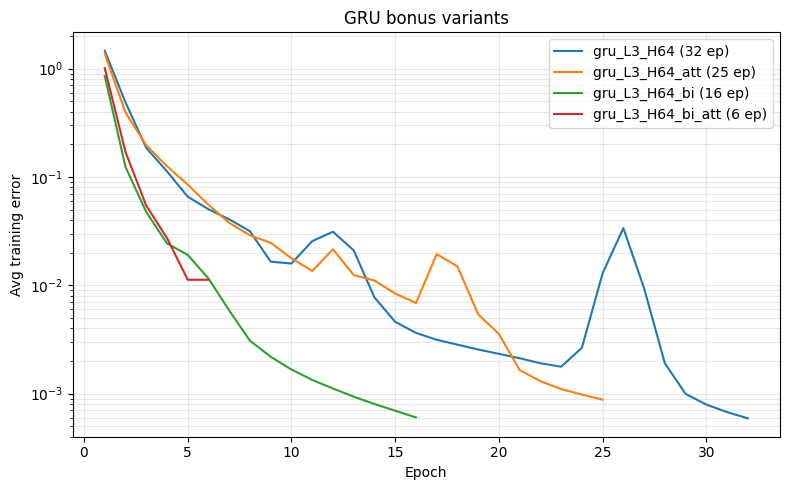

### Best bonus variant: gru_L3_H64_att  (params=65803, epochs=25)
Final training accuracy: 1.0000 | Validation: 0.9985 | Test accuracy: 0.9864
              precision    recall  f1-score   support

           0     0.9565    1.0000    0.9778       220
           1     0.9910    1.0000    0.9955       220
           2     0.9865    1.0000    0.9932       220
           3     0.9907    0.9682    0.9793       220
           4     0.9646    0.9909    0.9776       220
           5     1.0000    1.0000    1.0000       220
           6     1.0000    0.9455    0.9720       220
           7     0.9821    0.9955    0.9887       220
           8     0.9953    0.9636    0.9792       220
           9     1.0000    1.0000    1.0000       220

    accuracy                         0.9864      2200
   macro avg     0.9867    0.9864    0.9863      2200
weighted avg     0.9867    0.9864    0.9863      2200



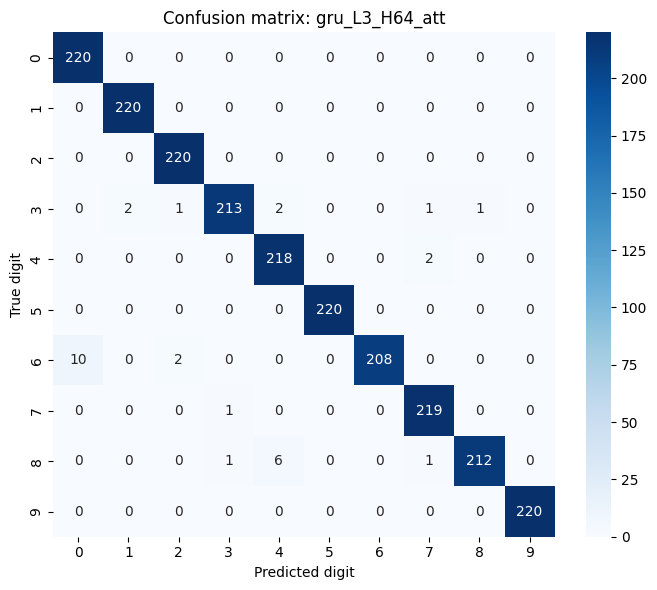

In [26]:
best_gru_cfg = best_by_cell['gru']['cfg']
bonus_variants = [dict(bidirectional=True), dict(attention=True), dict(bidirectional=True, attention=True)]
for v in bonus_variants:
    run_config({**best_gru_cfg, **v})        # skips automatically if already finished

eval_test_for_saved()                         # adds test_acc to the new JSONs

bonus = load_results(bonus=True)
cmp = make_table([best_by_cell['gru']] + bonus)
display(cmp.style.format({'train_acc': '{:.4f}', 'val_acc': '{:.4f}', 'test_acc': '{:.4f}'}))

plt.figure(figsize=(8, 5))
for r in [best_by_cell['gru']] + bonus:
    plt.plot(np.arange(1, r['epochs'] + 1), r['loss_hist'], label=f"{r['name']} ({r['epochs']} ep)")
plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('Avg training error'); plt.legend(); plt.grid(alpha=.3, which='both')
plt.title('GRU bonus variants'); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/loss_bonus.png', dpi=150); plt.show()

best_bonus = pick(bonus)
cm_bonus = report_best(best_bonus, 'Best bonus variant')

<h3>Auto-generated numbers for written analysis

In [27]:
g = df.groupby('cell').agg(mean_test=('test_acc', 'mean'), best_test=('test_acc', 'max'),
                           worst_test=('test_acc', 'min'), mean_epochs=('epochs', 'mean'),
                           mean_params=('params', 'mean'), mean_time_s=('time_s', 'mean'),
                           n_not_converged=('converged', lambda s: (~s).sum())).round(4)
print(g)
print('\nEffect of depth (mean test acc):\n', df.pivot_table(index='cell', columns='layers', values='test_acc').round(4))
print('\nEffect of width (mean test acc):\n', df.pivot_table(index='cell', columns='hidden', values='test_acc').round(4))
print('\nTrain-test gap (mean):\n', (df.train_acc - df.test_acc).groupby(df.cell).mean().round(4))

# Most-confused digit pairs for the best model
cm = cm_best.copy(); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]
print('\nTop confusions (true -> predicted, count):', [(int(a), int(b), int(cm[a, b])) for a, b in top])

      mean_test  best_test  worst_test  mean_epochs  mean_params  mean_time_s  \
cell                                                                            
gru      0.9589     0.9705      0.9345      33.7778   69076.6667      27.8889   
lstm     0.9565     0.9705      0.9473      34.5556   91850.0000      29.3333   
rnn      0.9061     0.9427      0.8586     148.6667   23530.0000     120.8889   

      n_not_converged  
cell                   
gru                 0  
lstm                0  
rnn                 7  

Effect of depth (mean test acc):
 layers       1       2       3
cell                          
gru     0.9503  0.9642  0.9623
lstm    0.9552  0.9556  0.9586
rnn     0.8841  0.9227  0.9114

Effect of width (mean test acc):
 hidden     32      64      128
cell                          
gru     0.9517  0.9552  0.9700
lstm    0.9497  0.9562  0.9635
rnn     0.8759  0.9173  0.9250

Train-test gap (mean):
 cell
gru     0.0410
lstm    0.0428
rnn     0.0739
dtype: float64

Top